# Rare/Core Double Sweep: Minimum Abundance x Prevalence (Recalled Species)

Do rare-excess or core-loss groups pick out **high-defense** plants once a species has to reach a minimum abundance to count as present?

In the earlier sweeps a species counted as present at any level above the table's 0.05% floor, so a single stray read made a species "present". Here presence needs at least `min_abundance` % of a plant's reads. That changes:

1. **Prevalence**, and so which species are rare (< prevalence threshold) or core (> threshold), using seasonal plant samples as before.
2. **Each plant's rare / core abundance**, which only counts species at or above `min_abundance` in that plant.

Minimum abundances: the current floor (0.05%), 0.1, 0.25, 0.5 and 1%.

**Two layers:**
- **Defense-score grid (fast):** every minimum abundance x prevalence threshold x group size, with the dysbiotic group picked either on absolute rare/core abundance (as in the earlier sweeps) or within timepoint (top `n` by within-timepoint z-score). The outcome is the timepoint-adjusted defense-score difference, compared with random groupings of the same size.
- **DESeq2 grid:** the original sweep's prevalence thresholds (rare < 5/10/20/30%, core > 70/80/90%) and group sizes (20, 40, 60, 100), absolute ranking, at each minimum abundance. Reports DE genes and how many of the 148 defense genes go up or down. Fits are cached in `Generated_data/dysbiosis_threshold_sweep_recalled_species/`; the current-floor runs reuse the original sweep's fits.

The defense score is only used to describe groups, never to define them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
from pathlib import Path
import statsmodels.formula.api as smf
from scipy.stats import zscore
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

from statsmodels.stats.multitest import multipletests

###Define Thresholds
min_abundances = [0.0, 0.1, 0.25, 0.5, 1.0]  # % of reads; 0.0 = the table's 0.05% floor (current definition)
# Defense-score grid
grid_rare_prevalences = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
grid_core_prevalences = [0.6, 0.7, 0.8, 0.9, 0.95]
grid_group_sizes = list(range(10, 151, 10))
n_null_groupings = 1000
# DESeq2 grid (as in the original sweep)
deseq_rare_prevalences = [0.05, 0.1, 0.2, 0.3]
deseq_core_prevalences = [0.7, 0.8, 0.9]
deseq_group_sizes = [20, 40, 60, 100]
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21
n_cpus = 10
results_dir = Path(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_threshold_sweep_recalled_species"
)

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

# Same gene filters as the dysbiosis DE notebook
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

# Defense score: only used to describe the groups, never to define them
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = set(defense_gene_list["gene"])
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_genes)
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

# Old species-level DE genes (59, plates 1-5), for overlap
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426
Genes kept for DESeq2: 18032


## Species abundance

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

# Transcriptome samples, all with a microbiome profile
de_samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(species_abundance_matrix.index)]
print("Transcriptomes with a microbiome profile:", len(de_samples), "of", len(trimmed_metadata))
sample_species = species_abundance_matrix.loc[trimmed_metadata.loc[de_samples, "sampID"]].set_index(de_samples)

Transcriptomes with a microbiome profile: 426 of 426


## Rare and core sets at each minimum abundance

How many species are rare or core under each presence rule.

In [4]:
timepoint = trimmed_metadata.loc[de_samples, "timepoint"]
defense_score = trimmed_metadata.loc[de_samples, "Defense Score"]
seasonal_matrix = species_abundance_matrix.loc[seasonal_samples]


def presence_rule(min_abundance):
    """Seasonal prevalence and the per-plant abundance matrix under a minimum-abundance rule."""
    if min_abundance == 0:
        return seasonal_prevalence, sample_species
    prevalence = (seasonal_matrix >= min_abundance).mean()
    return prevalence, sample_species.where(sample_species >= min_abundance, 0)


set_sizes = []
measures = {}  # (definition, min_abundance, prevalence) -> per-plant score, higher = more dysbiotic
for min_abundance in min_abundances:
    prevalence, counted = presence_rule(min_abundance)
    for p in sorted(set(grid_rare_prevalences) | set(deseq_rare_prevalences)):
        rare = prevalence.index[prevalence < p]
        measures[("rare excess", min_abundance, p)] = counted[rare.intersection(counted.columns)].sum(axis=1)
        set_sizes.append({"min abundance (%)": min_abundance, "definition": "rare excess", "prevalence": p, "n species": len(rare)})
    for p in sorted(set(grid_core_prevalences) | set(deseq_core_prevalences)):
        core = prevalence.index[prevalence > p]
        measures[("core loss", min_abundance, p)] = -counted[core.intersection(counted.columns)].sum(axis=1)
        set_sizes.append({"min abundance (%)": min_abundance, "definition": "core loss", "prevalence": p, "n species": len(core)})
pd.DataFrame(set_sizes).pivot_table(index=["definition", "prevalence"], columns="min abundance (%)", values="n species")

min abundance (%)        0.00   0.10   0.25   0.50   1.00
definition  prevalence                                   
core loss   0.60         63.0   51.0   28.0   13.0   10.0
            0.70         50.0   39.0   21.0   12.0    8.0
            0.80         40.0   30.0   16.0    9.0    4.0
            0.90         26.0   20.0   12.0    5.0    2.0
            0.95         19.0   17.0    7.0    3.0    2.0
rare excess 0.05        377.0  417.0  509.0  560.0  591.0
            0.10        434.0  474.0  545.0  585.0  612.0
            0.15        471.0  508.0  567.0  595.0  621.0
            0.20        493.0  533.0  581.0  605.0  627.0
            0.30        527.0  561.0  594.0  621.0  637.0
            0.40        554.0  575.0  609.0  628.0  642.0
            0.50        576.0  590.0  618.0  635.0  644.0

## Defense-score grid

For each measure and group size: the timepoint-adjusted defense difference (dysbiotic minus rest). The OLS is fitted once per timepoint design using the residual trick: defense and group indicator are both centred within timepoint, so the slope equals the `~ C(timepoint) + group` coefficient.

In [5]:
def within_timepoint_centre(values):
    return values - values.groupby(timepoint).transform("mean")


centred_defense = within_timepoint_centre(defense_score)
n_timepoints = timepoint.nunique()
n_total = len(de_samples)


def defense_difference(in_group):
    """Coefficient, SE and p of the group term in defense ~ C(timepoint) + group."""
    x = within_timepoint_centre(pd.Series(in_group.astype(float), index=de_samples))
    sxx = (x ** 2).sum()
    if sxx == 0:
        return np.nan, np.nan, np.nan
    beta = (x * centred_defense).sum() / sxx
    residual = centred_defense - beta * x
    df = n_total - n_timepoints - 1
    se = np.sqrt((residual ** 2).sum() / df / sxx)
    from scipy.stats import t as t_dist
    return beta, se, 2 * t_dist.sf(abs(beta / se), df)


def within_timepoint_z(score):
    grouped = score.groupby(timepoint)
    return ((score - grouped.transform("mean")) / grouped.transform("std")).fillna(0)


grid_rows = []
for (definition, min_abundance, p), score in measures.items():
    if p not in (grid_rare_prevalences if definition == "rare excess" else grid_core_prevalences):
        continue
    rankings = {
        "absolute": score.sort_values(ascending=False).index,
        "within timepoint": within_timepoint_z(score).sort_values(ascending=False).index,
    }
    for ranking, ordered in rankings.items():
        for n in grid_group_sizes:
            in_group = de_samples.isin(ordered[:n])
            beta, se, pval = defense_difference(in_group)
            grid_rows.append(
                {
                    "definition": definition, "min abundance (%)": min_abundance, "prevalence": p,
                    "ranking": ranking, "group size": n, "defense diff": beta, "SE": se, "p": pval,
                    "timepoints in group": timepoint[in_group].nunique(),
                }
            )
defense_grid = pd.DataFrame(grid_rows)
defense_grid["q"] = multipletests(defense_grid["p"].fillna(1), method="fdr_bh")[1]
defense_grid.to_csv(results_dir / "double_sweep_defense_grid.csv", index=False)
print(f"Groupings in the defense grid: {len(defense_grid)}")
print(f"Higher defense at q < 0.05: {((defense_grid['q'] < 0.05) & (defense_grid['defense diff'] > 0)).sum()}; "
      f"lower: {((defense_grid['q'] < 0.05) & (defense_grid['defense diff'] < 0)).sum()}")

Groupings in the defense grid: 1800
Higher defense at q < 0.05: 0; lower: 0


In [6]:
# Null: defense difference of random groupings of each size
rng = np.random.default_rng(0)
null_rows = []
for n in grid_group_sizes:
    diffs = [defense_difference(de_samples.isin(rng.choice(de_samples, n, replace=False)))[0] for _ in range(n_null_groupings)]
    null_rows.append({"group size": n, "null 2.5%": np.percentile(diffs, 2.5), "null 97.5%": np.percentile(diffs, 97.5), "null 99.9%": np.percentile(diffs, 99.9)})
null_table = pd.DataFrame(null_rows).set_index("group size")
defense_grid = defense_grid.join(null_table, on="group size")
defense_grid["above null 99.9%"] = defense_grid["defense diff"] > defense_grid["null 99.9%"]
print("Groupings above the 99.9th percentile of random groupings (higher defense):", defense_grid["above null 99.9%"].sum())
null_table.round(3)

Groupings above the 99.9th percentile of random groupings (higher defense): 1


,null 2.5%,null 97.5%,null 99.9%
group size,,,
10,-0.260,0.306,0.624
20,-0.199,0.225,0.392
30,-0.158,0.168,0.302
40,-0.141,0.146,0.246
50,-0.130,0.135,0.193
60,-0.122,0.123,0.196
70,-0.116,0.121,0.162
80,-0.100,0.108,0.151
90,-0.109,0.109,0.155


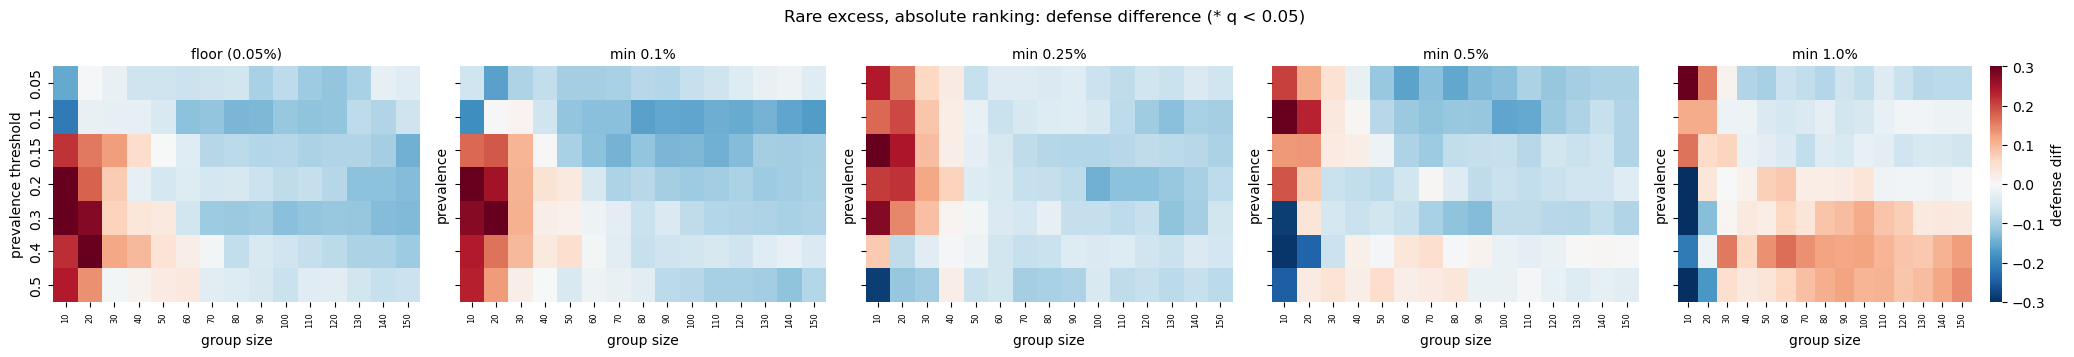

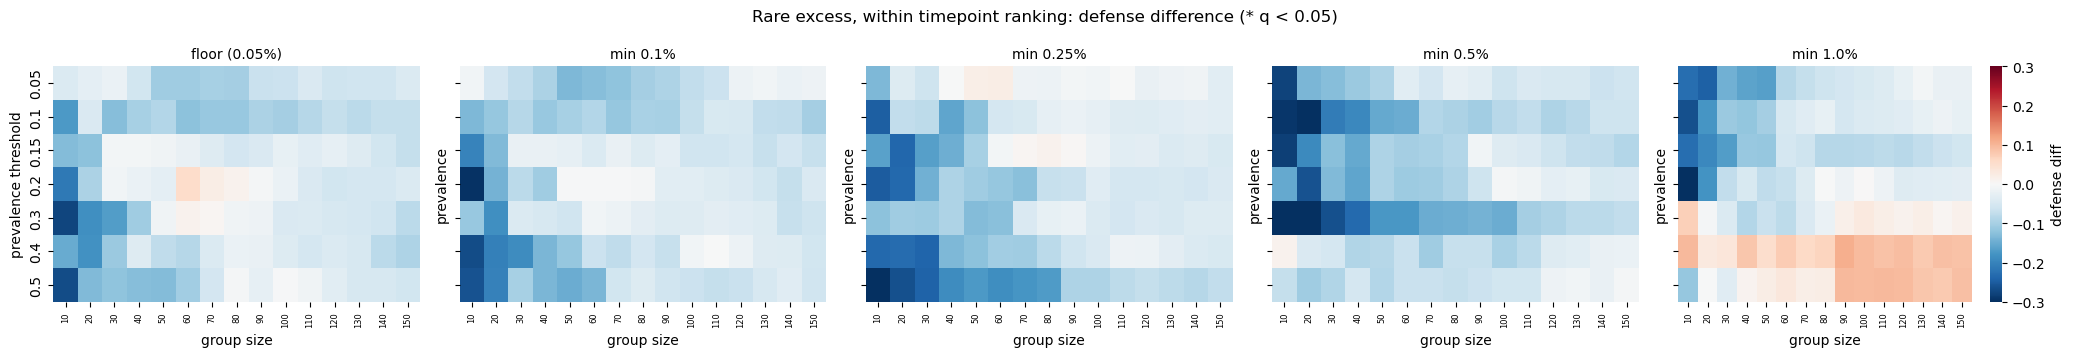

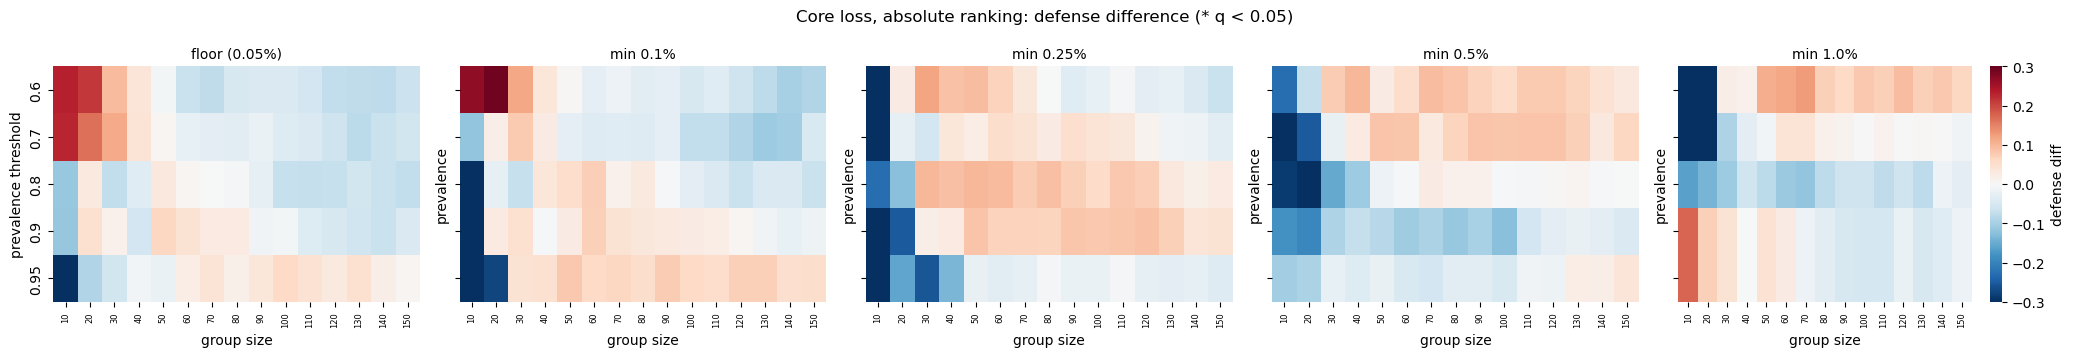

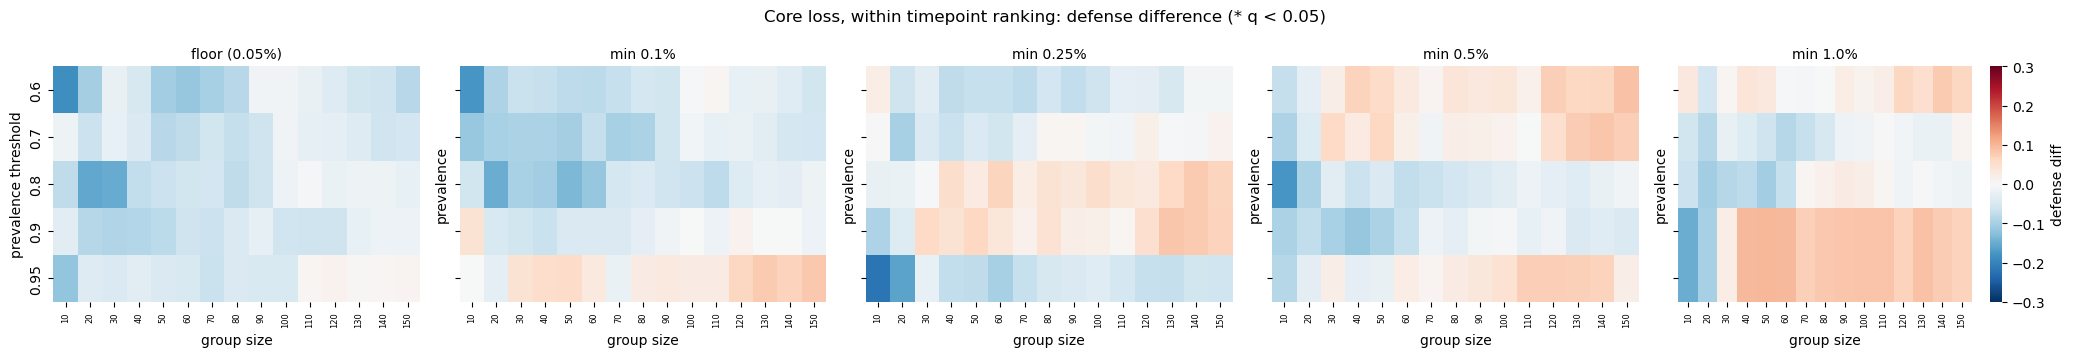

In [7]:
for definition in ["rare excess", "core loss"]:
    for ranking in ["absolute", "within timepoint"]:
        subset = defense_grid.loc[(defense_grid["definition"] == definition) & (defense_grid["ranking"] == ranking)]
        fig, axes = plt.subplots(1, len(min_abundances), figsize=(4.2 * len(min_abundances), 3.6), sharey=True)
        fig.patch.set_facecolor("white")
        for ax, min_abundance in zip(axes, min_abundances):
            grid = subset.loc[subset["min abundance (%)"] == min_abundance].pivot(index="prevalence", columns="group size", values="defense diff")
            stars = subset.loc[subset["min abundance (%)"] == min_abundance].pivot(index="prevalence", columns="group size", values="q")
            sns.heatmap(
                grid, cmap="RdBu_r", center=0, vmin=-0.3, vmax=0.3, ax=ax, cbar=ax is axes[-1],
                annot=stars.map(lambda q: "*" if q < 0.05 else ""), fmt="", annot_kws={"size": 9},
                cbar_kws={"label": "defense diff"},
            )
            ax.set_title(f"min {min_abundance}%" if min_abundance else "floor (0.05%)", fontsize=10)
            ax.set_xlabel("group size")
            ax.tick_params(axis="x", labelsize=6, rotation=90)
        axes[0].set_ylabel("prevalence threshold")
        fig.suptitle(f"{definition.capitalize()}, {ranking} ranking: defense difference (* q < 0.05)", fontsize=12)
        plt.tight_layout()
        plt.show()

In [8]:
print("Highest defense differences in the grid:")
defense_grid.sort_values("defense diff", ascending=False).head(25).round(4)

Highest defense differences in the grid:


,definition,min abundance (%),prevalence,ranking,group size,defense diff,SE,p,timepoints in group,q,null 2.5%,null 97.5%,null 99.9%,above null 99.9%
120,rare excess,0.00,0.30,absolute,10,0.5109,0.1449,0.0005,8,0.2397,-0.2601,0.3058,0.6245,False
90,rare excess,0.00,0.20,absolute,10,0.3761,0.1507,0.0130,7,0.3845,-0.2601,0.3058,0.6245,False
780,rare excess,0.25,0.15,absolute,10,0.3524,0.1532,0.0220,6,0.4422,-0.2601,0.3058,0.6245,False
1110,rare excess,0.50,0.10,absolute,10,0.3524,0.1532,0.0220,6,0.4422,-0.2601,0.3058,0.6245,False
151,rare excess,0.00,0.40,absolute,20,0.3277,0.1090,0.0028,12,0.2874,-0.1993,0.2250,0.3922,False
1440,rare excess,1.00,0.05,absolute,10,0.3272,0.1462,0.0258,8,0.4422,-0.2601,0.3058,0.6245,False
450,rare excess,0.10,0.20,absolute,10,0.3270,0.1463,0.0260,8,0.4422,-0.2601,0.3058,0.6245,False
481,rare excess,0.10,0.30,absolute,20,0.3101,0.1082,0.0044,12,0.3434,-0.1993,0.2250,0.3922,False
571,core loss,0.10,0.60,absolute,20,0.2927,0.1091,0.0076,12,0.3444,-0.1993,0.2250,0.3922,False
840,rare excess,0.25,0.30,absolute,10,0.2754,0.1465,0.0608,8,0.4592,-0.2601,0.3058,0.6245,False


## DESeq2 grid

Absolute ranking, as in the original sweep. The current-floor groupings have the same run IDs as the original sweep, so they load from cache.

In [9]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=n_cpus)
de_counts = cleaned_raw_transcriptome.loc[de_samples]
results_dir.mkdir(parents=True, exist_ok=True)


def run_deseq(run_id, high_samples):
    """DESeq2 ~timepoint + group (High vs Low) on all DE samples. Results are cached
    in results_dir, so a re-run only fits groupings it hasn't seen."""
    cache = results_dir / f"{run_id}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0)
    design_metadata = pd.DataFrame(
        {
            "timepoint": trimmed_metadata.loc[de_samples, "timepoint"],
            "group": np.where(de_samples.isin(high_samples), "High", "Low"),
        },
        index=de_samples,
    )
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts,
            metadata=design_metadata,
            design="~timepoint+group",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stats = pydeseq2.ds.DeseqStats(
            dds, contrast=["group", "High", "Low"], inference=inference, quiet=True
        )
        stats.summary()
    results = stats.results_df
    results.to_csv(cache)
    return results


def summarise_run(results, high_samples):
    """DE gene counts, plus how the group's defense score compares (timepoint-adjusted)."""
    significant = results.loc[results["padj"] < 0.05]
    defense_df = trimmed_metadata.loc[de_samples, ["timepoint", "Defense Score"]].assign(
        high=de_samples.isin(high_samples).astype(int)
    )
    fit = smf.ols("Q('Defense Score') ~ C(timepoint) + high", data=defense_df).fit()
    return {
        "n High": int(defense_df["high"].sum()),
        "significant (padj < 0.05)": len(significant),
        "up": int((significant["log2FoldChange"] > 0).sum()),
        "down": int((significant["log2FoldChange"] < 0).sum()),
        "significant, |LFC| > 1": int((significant["log2FoldChange"].abs() > 1).sum()),
        "min padj": results["padj"].min(),
        "defense genes among significant": len(set(significant.index) & defense_genes),
        "old DE genes among significant": len(set(significant.index) & old_de_genes),
        "defense score diff (timepoint-adjusted)": fit.params["high"],
        "defense score diff p": fit.pvalues["high"],
    }

In [10]:
def top_n_group(score, n):
    ordered = score.sort_values(ascending=False)
    # core-loss scores are negative core abundance, so report the cutoff as a positive %
    return ordered.index[:n], abs((ordered.iloc[n - 1] + ordered.iloc[n]) / 2)


deseq_rows = []
for min_abundance in min_abundances:
    for definition, prevalences in [("rare excess", deseq_rare_prevalences), ("core loss", deseq_core_prevalences)]:
        for p in prevalences:
            score = measures[(definition, min_abundance, p)]
            for n in deseq_group_sizes:
                high_samples, cutoff = top_n_group(score, n)
                base_id = f"{definition.replace(' ', '_')}_prev{p:g}_n{n}"
                run_id = base_id if min_abundance == 0 else f"minabund{min_abundance:g}_{base_id}"
                deseq_rows.append(
                    {
                        "definition": definition, "min abundance (%)": min_abundance, "prevalence": p, "group size": n,
                        "cutoff (% of reads)": round(cutoff, 3), "run_id": run_id, "high_samples": high_samples,
                    }
                )
deseq_grid = pd.DataFrame(deseq_rows)
deseq_grid["sample_key"] = deseq_grid["high_samples"].map(lambda s: tuple(sorted(s)))
deseq_grid["fit_id"] = deseq_grid.groupby("sample_key")["run_id"].transform("first")
cached = deseq_grid.drop_duplicates("fit_id")["fit_id"].map(lambda f: (results_dir / f"{f}.csv").exists())
print(f"DESeq2 groupings: {len(deseq_grid)}, distinct: {deseq_grid['fit_id'].nunique()}, cached: {cached.sum()}, to fit: {(~cached).sum()}")

DESeq2 groupings: 140, distinct: 137, cached: 28, to fit: 109


In [11]:
fit_results = {}
summary_rows = []
for _, row in deseq_grid.iterrows():
    if row["fit_id"] not in fit_results:
        fit_results[row["fit_id"]] = run_deseq(row["fit_id"], row["high_samples"])
    results = fit_results[row["fit_id"]]
    defense_results = results.loc[results.index.isin(defense_genes)]
    defense_significant = defense_results["padj"] < 0.05
    summary_rows.append(
        {
            **row.drop(["high_samples", "sample_key"]).to_dict(),
            **summarise_run(results, row["high_samples"]),
            "defense genes up": int((defense_significant & (defense_results["log2FoldChange"] > 0)).sum()),
            "defense genes down": int((defense_significant & (defense_results["log2FoldChange"] < 0)).sum()),
            "median defense gene LFC": defense_results["log2FoldChange"].median(),
        }
    )
deseq_summary = pd.DataFrame(summary_rows)
deseq_summary.to_csv(results_dir / "double_sweep_deseq_summary.csv", index=False)
print(f"Groupings with >= 10 defense genes up: {(deseq_summary['defense genes up'] >= 10).sum()} of {len(deseq_summary)}")

Groupings with >= 10 defense genes up: 0 of 140


In [12]:
deseq_columns = [
    "definition", "min abundance (%)", "prevalence", "group size", "cutoff (% of reads)",
    "significant (padj < 0.05)", "defense genes up", "defense genes down", "median defense gene LFC",
    "defense score diff (timepoint-adjusted)", "defense score diff p",
]
print("Most defense genes up:")
deseq_summary.sort_values(["defense genes up", "defense score diff (timepoint-adjusted)"], ascending=False)[deseq_columns].head(25).round(4)

Most defense genes up:


,definition,min abundance (%),prevalence,group size,cutoff (% of reads),significant (padj < 0.05),defense genes up,defense genes down,median defense gene LFC,defense score diff (timepoint-adjusted),defense score diff p
99,rare excess,0.50,0.30,100,17.099,1305,7,15,-0.0881,-0.0773,0.1705
107,core loss,0.50,0.80,100,35.042,83,4,0,0.0007,-0.0027,0.9611
23,core loss,0.00,0.80,100,72.432,635,4,9,-0.0984,-0.0690,0.2447
111,core loss,0.50,0.90,100,19.662,454,4,3,-0.0684,-0.1264,0.0157
113,rare excess,1.00,0.05,40,6.703,362,3,4,-0.0905,-0.0898,0.2679
64,rare excess,0.25,0.20,20,17.860,140,2,0,0.0272,0.2166,0.0469
8,rare excess,0.00,0.20,20,9.498,52,2,0,-0.0064,0.1777,0.1068
68,rare excess,0.25,0.30,20,23.451,103,2,0,0.0153,0.1453,0.1756
92,rare excess,0.50,0.20,20,23.305,107,2,0,-0.0332,0.0751,0.4951
21,core loss,0.00,0.80,40,62.714,216,2,1,-0.0629,-0.0373,0.6662


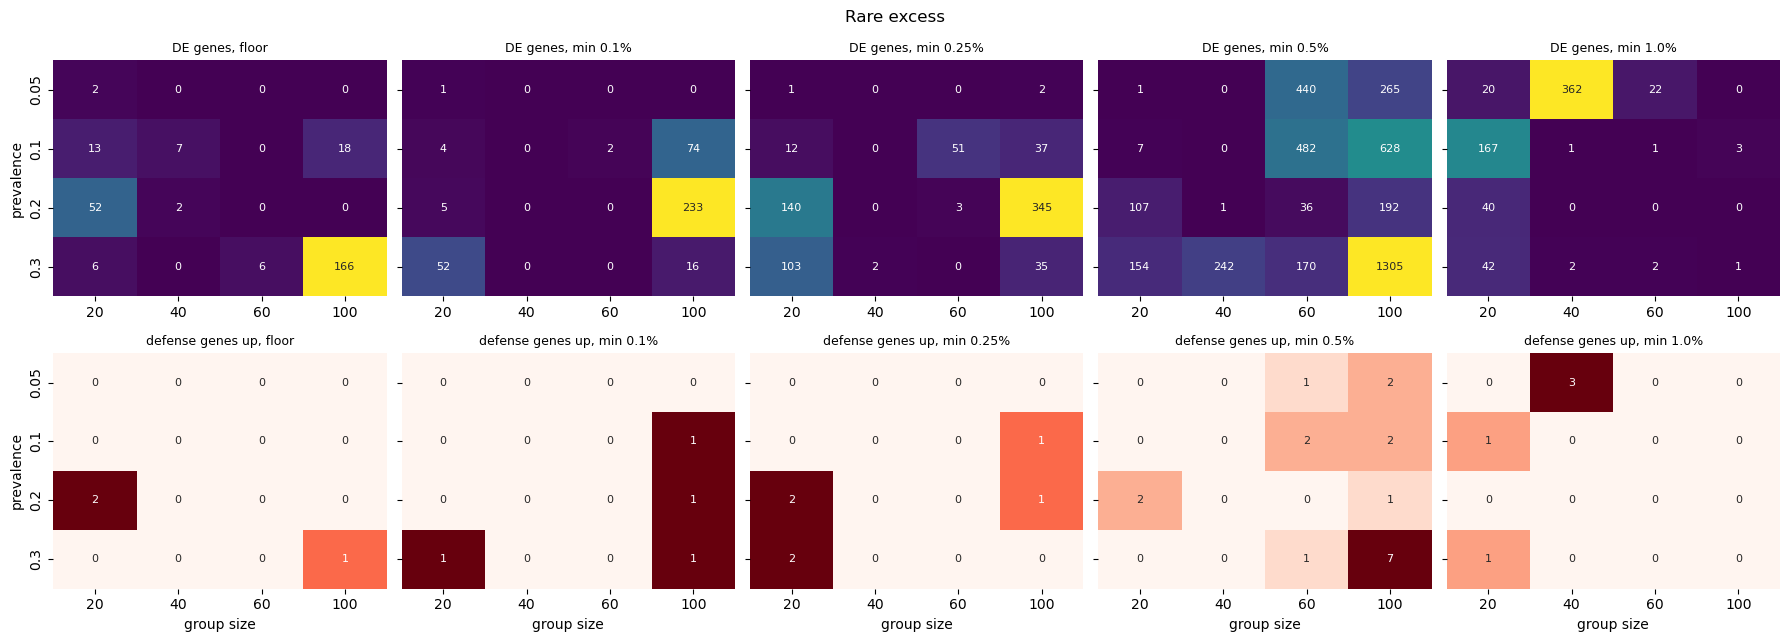

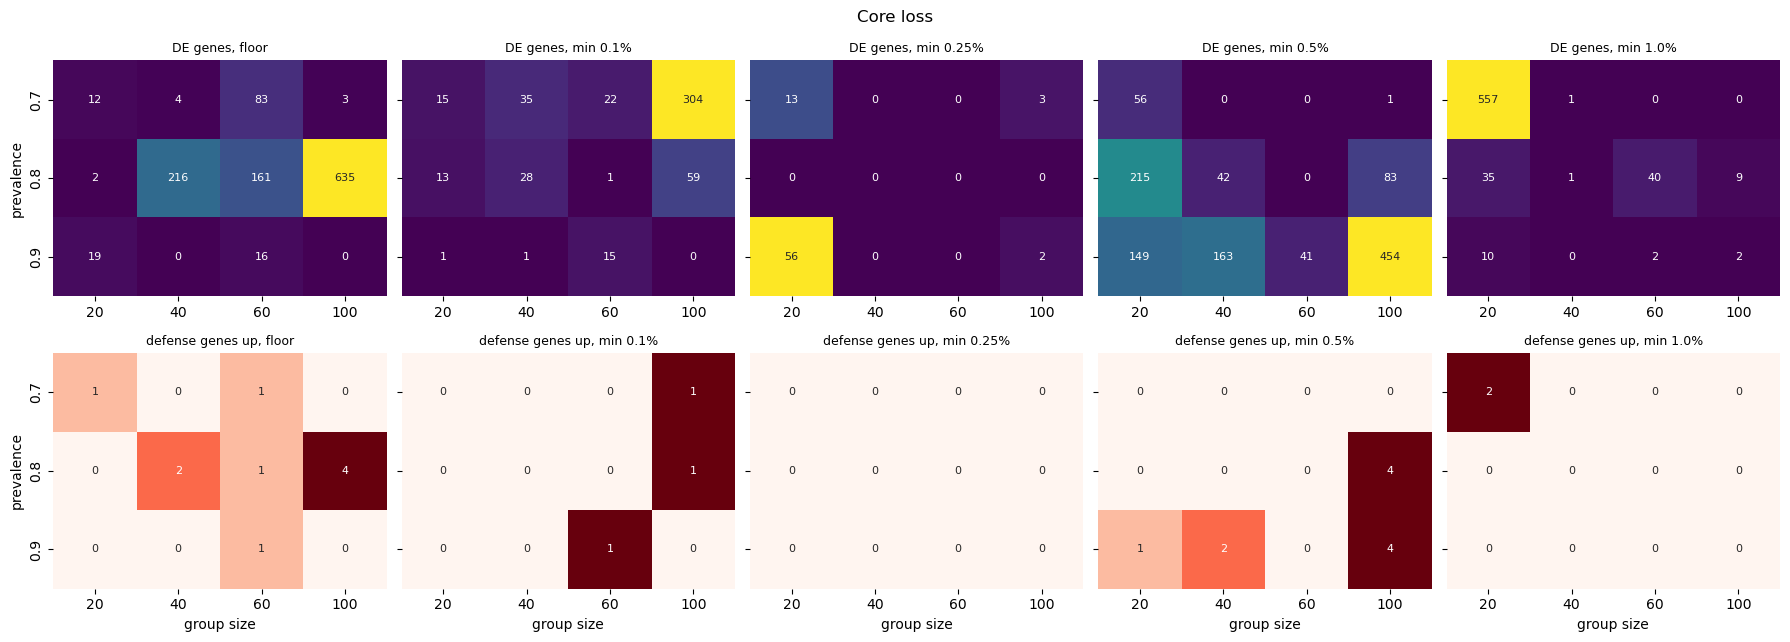

In [13]:
for definition in ["rare excess", "core loss"]:
    subset = deseq_summary.loc[deseq_summary["definition"] == definition]
    fig, axes = plt.subplots(2, len(min_abundances), figsize=(3.6 * len(min_abundances), 6.5), sharey=True)
    fig.patch.set_facecolor("white")
    for column, min_abundance in enumerate(min_abundances):
        part = subset.loc[subset["min abundance (%)"] == min_abundance]
        for row, (value, label, cmap) in enumerate(
            [("significant (padj < 0.05)", "DE genes", "viridis"), ("defense genes up", "defense genes up", "Reds")]
        ):
            ax = axes[row, column]
            grid = part.pivot(index="prevalence", columns="group size", values=value)
            sns.heatmap(grid, annot=True, fmt=".0f", cmap=cmap, cbar=False, annot_kws={"size": 8}, ax=ax)
            ax.set_title(f"{label}, min {min_abundance}%" if min_abundance else f"{label}, floor", fontsize=9)
            ax.set_xlabel("group size" if row == 1 else "")
            ax.set_ylabel("prevalence" if column == 0 else "")
    fig.suptitle(definition.capitalize(), fontsize=12)
    plt.tight_layout()
    plt.show()